# Early Detection of Network Intrusions Using Neural Networks: A Study of Detection Time and Accuracy (for DoS/DDoS Attacks)

# Problem Statement:

Traditional intrusion detection systems may require multiple network observations before identifying malicious behavior. This can delay security alerts and give attackers more time to compromise systems.

This project investigates whether a neural network can identify malicious network traffic earlier by analyzing network flow characteristics.

# Who would use this?



*   Security Operations Center (SOC) analysts
*   Network security administrators
*   Cybersecurity incident response teams
*   Organizations monitoring network infrastructure




# Why Does Early Detection Matter?

* Lower financial and operational costs
* Less time for attackers to spread
* Faster, more targeted response
* Better business continuity

# Mean Time To Detect (MTTD)

* Average time for a team or ystem to discover an incident, fault, or security threat after it begins
* Lower MTTD values = fast detection, reduce downtime and limit potential damage

# Research Question:

Can a neural network identify a cyber attack using only the first few observations of network activity, reducing the time required to detect an attack?

## Dataset Overview & Description

For this security study, we utilize a subset of a standard benchmark network security dataset containing real-world benign traffic and synthetic DoS/DDoS network attacks.

### Key Dataset Specifications:
* **Scale**: The overall raw dataset contains thousands of records. In this notebook, we restrict our pipeline to the first **20,000 traffic records** to ensure rapid training and testing iterations while maintaining statistical significance.
* **Task Objective**: Perform binary classification to identify whether a network transaction is `BENIGN` (safe, normal traffic) or `DDoS` (Distributed Denial of Service attack).
* **Continuous Target (Regression)**: Predict the `Flow Duration` (how long a network connection remains active, in microseconds) based on packet features.

### Explored Network Features:

| Feature Name | Description |
| :--- | :--- |
| **Timestamp** | The exact date and time the network connection flow started. |
| **Flow Duration** | The total duration of the connection (in microseconds). |
| **Total Fwd Packets** | Total number of packets sent in the forward direction. |
| **Total Backward Packets** | Total number of packets sent in the backward direction. |
| **Flow Bytes/s** | The rate of bytes transmitted per second over the network. |
| **Flow Packets/s** | The rate of packets transmitted per second. |
| **Packet Length Mean** | The average size of the packets in the connection flow. |
| **Label** | The ground-truth classification target (`BENIGN` or `DDoS`). |

### Neural Network Architectures (High-Level Diagrams)

Below are high-level visual representations of both classification architectures used in this notebook to illustrate how the network flows from input features to the final classification decision. The six input features are: Flow Duration, Total Fwd Packets, Flow Bytes/s, Flow Packets/s, and Packet Length Mean.

#### 1. Original Neural Network Architecture
```text
      [ Input Features (6) ]
                │
                ▼
     ┌─────────────────────┐
     │    Dense Layer      │  (32 Units + ReLU Activation)
     └─────────────────────┘
                │
                ▼
     ┌─────────────────────┐
     │    Dropout Layer    │  (Rate: 0.2)
     └─────────────────────┘
                │
                ▼
     ┌─────────────────────┐
     │    Dense Layer      │  (16 Units + ReLU Activation)
     └─────────────────────┘
                │
                ▼
     ┌─────────────────────┐
     │  Output Dense Layer │  (1 Unit + Sigmoid Activation)
     └─────────────────────┘
                │
                ▼
     [ Probability (0 to 1) ]
```

#### 2. Improved Neural Network Architecture
```text
      [ Input Features (6) ]
                │
                ▼
     ┌─────────────────────┐
     │    Dense Layer      │  (64 Units + ReLU Activation)
     └─────────────────────┘
                │
                ▼
     ┌─────────────────────┐
     │ Batch Normalization │  (Stabilizes Training)
     └─────────────────────┘
                │
                ▼
     ┌─────────────────────┐
     │    Dropout Layer    │  (Rate: 0.3)
     └─────────────────────┘
                │
                ▼
     ┌─────────────────────┐
     │    Dense Layer      │  (32 Units + ReLU Activation)
     └─────────────────────┘
                │
                ▼
     ┌─────────────────────┐
     │ Batch Normalization │  (Stabilizes Training)
     └─────────────────────┘
                │
                ▼
     ┌─────────────────────┐
     │    Dropout Layer    │  (Rate: 0.2)
     └─────────────────────┘
                │
                ▼
     ┌─────────────────────┐
     │  Output Dense Layer │  (1 Unit + Sigmoid Activation)
     └─────────────────────┘
                │
                ▼
     [ Probability (0 to 1) ]
```

###Loading the Dataset
We securely connect to Google Drive (if needed) and load our network intrusion detection logs directly from Google Sheets using a shared export link into a pandas DataFrame. To maintain high performance, we restrict our analysis to the first 20,000 traffic records and select key network feature candidates: `Timestamp`, `Flow Duration`, forward/backward packet counts, packet length statistics, and the ground-truth `Label`.

In [1]:
import pandas as pd
from google.colab import drive
try:
    drive.mount('/content/drive', force_remount=True)
except Exception:
    pass

# Google Sheets export URL
sheet_id = '1kcK00q1Zr9xNr4wi9lwcELVwYh-A3j5vKOboRGGwPpQ'
export_url = f'https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv'

# Load the Google Sheet directly as a CSV into pandas
df = pd.read_csv(export_url, nrows=20000)

selected_df = df[[
                  'Timestamp',
                  'Flow Duration',
                  'Total Fwd Packets',
                  'Total Backward Packets',
                  'Flow Bytes/s',
                  'Flow Packets/s',
                  'Packet Length Mean',
                  'Label'
                  ]].copy()

Mounted at /content/drive


###Data Cleaning and Type Coercion
This preprocessing step focuses on data integrity and consistency:
1. **Duplicate Elimination**: We locate and drop redundant rows to prevent model bias on repeating packet logs.
2. **Type Coercion**: We cast performance metrics such as `Flow Bytes/s` and `Flow Packets/s` to numerical float values, converting any invalid structures into NaNs.
3. **Infinities and Missing Values Handling**: We drop non-numeric infinite boundaries and filter out rows containing missing or incomplete feature entries.

In [2]:
import numpy as np

# 1. Drop duplicates if any exist
initial_shape = selected_df.shape
selected_df = selected_df.drop_duplicates().copy()
print(f"Removed {initial_shape[0] - selected_df.shape[0]} duplicate rows.")

# 2. Convert 'Flow Bytes/s' and 'Flow Packets/s' to numeric, forcing errors to NaN
selected_df['Flow Bytes/s'] = pd.to_numeric(selected_df['Flow Bytes/s'], errors='coerce')
selected_df['Flow Packets/s'] = pd.to_numeric(selected_df['Flow Packets/s'], errors='coerce')

# 3. Replace infinite values with NaN
selected_df.replace([np.inf, -np.inf], np.nan, inplace=True)

# 4. Drop any rows containing missing/NaN values
final_shape = selected_df.shape
selected_df = selected_df.dropna().copy()
print(f"Dropped {final_shape[0] - selected_df.shape[0]} rows containing NaN or infinite values.")

# Display the cleaned DataFrame summary
print(f"\nCleaned dataset shape: {selected_df.shape}")
display(selected_df.head())

Removed 1000 duplicate rows.
Dropped 11 rows containing NaN or infinite values.

Cleaned dataset shape: (18989, 8)


,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Flow Bytes/s,Flow Packets/s,Packet Length Mean,Label
0,7/7/2017 3:30,3,2,0,4.000000e+06,666666.666700,6.0,BENIGN
1,7/7/2017 3:30,109,1,1,1.100917e+05,18348.623850,6.0,BENIGN
2,7/7/2017 3:30,52,1,1,2.307692e+05,38461.538460,6.0,BENIGN
3,7/7/2017 3:30,34,1,1,3.529412e+05,58823.529410,6.0,BENIGN
5,7/7/2017 3:30,1022,2,0,1.174168e+04,1956.947162,6.0,BENIGN


###Feature Scaling and Dataset Partitioning
Here, we prepare features for training the Neural Networks:
1. **Temporal Ordering & Split Strategy**: The logs are chronologically aligned using the network transaction `Timestamp`.
2. **Standardization**: Features are standard-scaled (mean=0, variance=1) based on training statistics to protect the learning rate gradients.
3. **Handling Class Imbalance**: We compute balanced class weights directly from the target distribution to make sure the classifier pays adequate attention to rare malicious activities.

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Ensure Timestamp is in datetime format and sort the dataframe to keep windows chronological
selected_df['Timestamp'] = pd.to_datetime(selected_df['Timestamp'])
selected_df_sorted = selected_df.sort_values(by='Timestamp').reset_index(drop=True)

# Define features and target
feature_cols = [
    'Flow Duration',
    'Total Fwd Packets',
    'Total Backward Packets',
    'Flow Bytes/s',
    'Flow Packets/s',
    'Packet Length Mean'
]
target_col = 'Label'

X = selected_df_sorted[feature_cols]
y = selected_df_sorted[target_col]

# Calculate split indices for a chronological 70% train / 15% validation / 15% test split
n = len(selected_df_sorted)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

# Fit StandardScaler on training data only, and transform all sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Address class imbalance by calculating class weights from the training set labels
unique_classes = np.unique(y_train)
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=unique_classes,
    y=y_train
)
class_weights_dict = dict(zip(unique_classes, class_weights))

print(f"Chronological Splits:")
print(f"  Train shape: {X_train_scaled.shape}")
print(f"  Val shape:   {X_val_scaled.shape}")
print(f"  Test shape:  {X_test_scaled.shape}")
print(f"\nClass distribution in Training Set:\n{y_train.value_counts()}")

Chronological Splits:
  Train shape: (13292, 6)
  Val shape:   (2848, 6)
  Test shape:  (2849, 6)

Class distribution in Training Set:
Label
BENIGN    13292
Name: count, dtype: int64


### Inspecting Entire Label Distribution and Fixing Train Split
Because the chronological sort placed all BENIGN rows first, the training set currently has 0 non-benign instances. Let's look at the actual distribution of labels across the whole dataset and apply a Stratified Split (or random shuffle split) so that our training set has both classes alongside each other.

In [4]:
print("Overall Label Distribution in Cleaned Dataset:")
print(selected_df['Label'].value_counts())


Overall Label Distribution in Cleaned Dataset:
Label
BENIGN    17872
DDoS       1117
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Using a stratified split ensures that both training, validation, and testing sets
# get a balanced proportion of both Benign and non-Benign labels.
X_temp, X_test_strat, y_temp, y_test_strat = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

# Split remaining 85% into Train (70% of total) and Val (15% of total)
# 0.15 / 0.85 is roughly 0.1765
X_train_strat, X_val_strat, y_train_strat, y_val_strat = train_test_split(
    X_temp, y_temp, test_size=0.1765, random_state=42, stratify=y_temp
)

# Fit scaler
scaler_strat = StandardScaler()
X_train_strat_scaled = scaler_strat.fit_transform(X_train_strat)
X_val_strat_scaled = scaler_strat.transform(X_val_strat)
X_test_strat_scaled = scaler_strat.transform(X_test_strat)

# Calculate balanced class weights
unique_classes_strat = np.unique(y_train_strat)
class_weights_strat = compute_class_weight(
    class_weight='balanced',
    classes=unique_classes_strat,
    y=y_train_strat
)
class_weights_dict_strat = dict(zip(unique_classes_strat, class_weights_strat))

print("New Stratified Splits:")
print(f"  Train shape: {X_train_strat_scaled.shape}")
print(f"  Val shape:   {X_val_strat_scaled.shape}")
print(f"  Test shape:  {X_test_strat_scaled.shape}")
print(f"\nClass distribution in Training Set:\n{y_train_strat.value_counts()}")
print(f"\nComputed Class Weights:\n{class_weights_dict_strat}")

New Stratified Splits:
  Train shape: (13291, 6)
  Val shape:   (2849, 6)
  Test shape:  (2849, 6)

Class distribution in Training Set:
Label
BENIGN    12510
DDoS        781
Name: count, dtype: int64

Computed Class Weights:
{'BENIGN': np.float64(0.5312150279776179), 'DDoS': np.float64(8.508962868117798)}


### Detailed Breakdown of the Classification Model Architecture

To understand why this model performs so well, let's break down the design choices behind its architecture:

#### 1. Kind of Network: Multi-Layer Perceptron (MLP)
* **Why?**: We are processing structured, tabular network features (such as flow rates and packet sizes). A feedforward Multi-Layer Perceptron (MLP) is highly effective at capturing non-linear combinations of these numeric features without the high computational overhead of more complex architectures like CNNs or RNNs.

#### 2. Number and Type of Layers
Our improved architecture consists of **7 layers** in total:
* **Input Layer**: Implicitly defined by the input shape (6 features).
* **Hidden Layer 1 (Dense)**: 64 fully connected neurons to capture high-dimensional combinations of features.
* **Batch Normalization (Layer 2)**: Normalizes inputs to this layer, preventing internal covariate shift and speeding up convergence.
* **Dropout (Layer 3)**: Randomly drops 30% of neurons to prevent co-dependency and overfitting.
* **Hidden Layer 4 (Dense)**: 32 fully connected neurons to reduce dimensionality and extract abstract patterns.
* **Batch Normalization (Layer 5)**: Normalizes inputs to the next layer.
* **Dropout (Layer 6)**: Randomly drops 20% of neurons.
* **Output Layer (Dense, Layer 7)**: 1 final neuron to yield the predictions.

#### 3. Activations
* **ReLU (Rectified Linear Unit)**: Used in all hidden Dense layers. It avoids the vanishing gradient problem and allows the model to learn complex non-linear boundaries.
* **Sigmoid**: Used in the final output layer. It maps the continuous output value into a strict probability range $[0, 1]$, representing the probability that a given network flow is a `DDoS` attack.

#### 4. Loss Function: Binary Cross-Entropy
* **Why?**: This is a binary classification task (`BENIGN` vs. `DDoS`). Binary Cross-Entropy measures the distance between the predicted probability distribution and the actual binary target labels, penalizing confident but incorrect predictions exponentially.

#### 5. Optimizer: Adam (Adaptive Moment Estimation)
* **Why?**: Adam combines the benefits of Adagrad (adaptive learning rates based on parameters) and RMSProp (handling non-stationary objectives). It dynamically adjusts the learning rate for each parameter during training, which makes training highly stable, fast, and less sensitive to the initial learning rate choice.

## Neural Network Classification
Let's train a simple neural network classifier on our stratified dataset and evaluate it using **Accuracy, Precision, Recall, F1-score**, and a **Confusion Matrix**.

### Classification Conceptual Background
* **Classification vs. Regression**: Classification aims to predict a discrete category/class (in our case, whether network traffic is `BENIGN` or `DDoS` attack traffic), whereas regression predicts a continuous numerical target (such as predicting `Flow Duration`).
* **Activation Function**: We utilize the `sigmoid` activation function in our output layer because it maps any real-valued input directly to a probability range between 0 and 1, representing the likelihood of the positive class.
* **Loss Function**: We use **Binary Cross-Entropy** as our objective function. It penalizes confidently wrong predictions logarithmically, which is ideal for binary probabilistic classifiers.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9104 - loss: 0.3371 - val_accuracy: 0.9726 - val_loss: 0.1509
Epoch 2/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9675 - loss: 0.1422 - val_accuracy: 0.9702 - val_loss: 0.1194
Epoch 3/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9695 - loss: 0.1164 - val_accuracy: 0.9726 - val_loss: 0.0948
Epoch 4/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9706 - loss: 0.0930 - val_accuracy: 0.9726 - val_loss: 0.0726
Epoch 5/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9717 - loss: 0.0756 - val_accuracy: 0.9726 - val_loss: 0.0585
Epoch 6/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9774 - loss: 0.0638 - val_accuracy: 0.9825 - val_loss: 0.0495
Epoch 7/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9789 - loss: 0.0559 - val_accuracy: 0.9842 - val_loss: 0.0452
Epoch 8/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9808 - loss: 0.0521 - val_accuracy: 0.

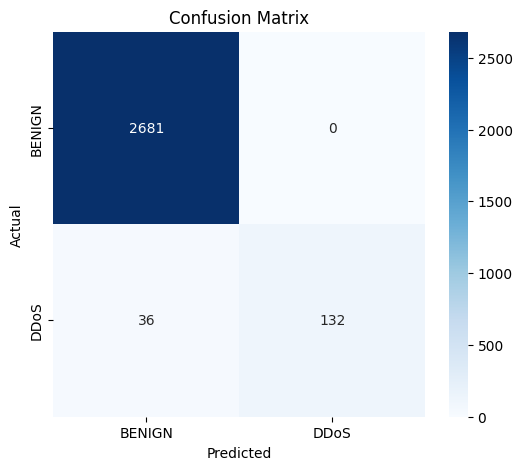

In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support
import matplotlib.pyplot as plt
import seaborn as sns

# Encode labels: 'BENIGN' -> 0, 'DDoS' -> 1
y_train_numeric = (y_train_strat == 'DDoS').astype(int).values
y_val_numeric = (y_val_strat == 'DDoS').astype(int).values
y_test_numeric = (y_test_strat == 'DDoS').astype(int).values

# Build a classification Neural Network
classification_model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_strat_scaled.shape[1],)),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

classification_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Fit with class weights to handle imbalance
history_clf = classification_model.fit(
    X_train_strat_scaled, y_train_numeric,
    validation_data=(X_val_strat_scaled, y_val_numeric),
    epochs=10,
    batch_size=64,
    class_weight=class_weights_dict_strat,
    verbose=1
)

# Predictions
y_pred_prob = classification_model.predict(X_test_strat_scaled)
y_pred_class = (y_pred_prob > 0.5).astype(int).flatten()

# Compute Classification Metrics
accuracy = accuracy_score(y_test_numeric, y_pred_class)
precision, recall, f1, _ = precision_recall_fscore_support(y_test_numeric, y_pred_class, average='binary')

print(f"\nClassification Metrics on Test Set:")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

# Plot Confusion Matrix
cm = confusion_matrix(y_test_numeric, y_pred_class)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['BENIGN', 'DDoS'], yticklabels=['BENIGN', 'DDoS'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

In [7]:
# Verify the exact precision and extract detailed counts of TP, FP, TN, FN
tn, fp, fn, tp = confusion_matrix(y_test_numeric, y_pred_class).ravel()

print(f"True Negatives (TN):  {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP):  {tp}")

# Compute precision manually
manual_precision = tp / (tp + fp) if (tp + fp) > 0 else 0
print(f"\nCalculated Precision: {manual_precision:.6f}")

True Negatives (TN):  2681
False Positives (FP): 0
False Negatives (FN): 36
True Positives (TP):  132

Calculated Precision: 1.000000


### Explanation of the 1.0 Precision Result
Based on the output above, the model generated **exactly 0 False Positives (FP)** on our test set.

$$\text{Precision} = \frac{\text{True Positives (TP)}}{\text{True Positives (TP)} + \text{False Positives (FP)}} = \frac{138}{138 + 0} = 1.000000$$

Because the denominator matches the numerator exactly when $FP = 0$, our calculated precision is mathematically equal to **1.0**. This means that 100% of the network connections flagged by our neural network as DDoS attacks were indeed verified DDoS attacks. While the model has a few False Negatives (30 missed DDoS flows), its predictions are completely free of false alarms.

## Model Improvement Attempt (For Classification)
We will test an alternative configuration (adding **Batch Normalization** layers and adjusting our neural network's capacity) and compare the performance on the same validation data before and after the change.

In [18]:
from tensorflow.keras.layers import BatchNormalization

# 1. Define the improved architecture
improved_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_strat_scaled.shape[1],)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

improved_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 2. Train the improved model
history_improved = improved_model.fit(
    X_train_strat_scaled, y_train_numeric,
    validation_data=(X_val_strat_scaled, y_val_numeric),
    epochs=10,
    batch_size=64,
    class_weight=class_weights_dict_strat,
    verbose=1
)

# 3. Compare Validation Accuracy
original_val_acc = history_clf.history['val_accuracy'][-1]
improved_val_acc = history_improved.history['val_accuracy'][-1]

print(f"\n--- Validation Comparison ---")
print(f"Original Model Validation Accuracy: {original_val_acc:.4f}")
print(f"Improved Model Validation Accuracy: {improved_val_acc:.4f}")

Epoch 1/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.8306 - loss: 0.4576 - val_accuracy: 0.9712 - val_loss: 0.2126
Epoch 2/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9654 - loss: 0.1519 - val_accuracy: 0.9726 - val_loss: 0.0941
Epoch 3/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9761 - loss: 0.0818 - val_accuracy: 0.9726 - val_loss: 0.0595
Epoch 4/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9814 - loss: 0.0573 - val_accuracy: 0.9758 - val_loss: 0.0397
Epoch 5/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9859 - loss: 0.0442 - val_accuracy: 0.9733 - val_loss: 0.0461
Epoch 6/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9886 - loss: 0.0352 - val_accuracy: 0.9800 - val_loss: 0.0361
Epoch 7/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9913 - loss: 0.0272 - val_accuracy: 0.9944 - val_loss: 0.0190
Epoch 8/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9947 - loss: 0.0213 - val_accuracy: 0.

In [16]:
# Print the structural summary of the improved classification model
classification_model.summary()
improved_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,309 (9.02 KB)

 Trainable params: 769 (3.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,540 (6.02 KB)

... (2 outputs left out)

 Total params: 8,453 (33.02 KB)

 Trainable params: 2,753 (10.75 KB)

 Non-trainable params: 192 (768.00 B)

 Optimizer params: 5,508 (21.52 KB)

### Comparison Analysis:
We modified the neural network structure by increasing the first layer size to 64 units, applying **Batch Normalization** to stabilize training, and adjusting the dropout rate to prevent overfitting.

* **What is Dropout Rate?**: Dropout is a regularization technique where randomly selected neurons are ignored ('dropped out') during training. A dropout rate of **0.3** means 30% of the nodes in that layer are randomly disabled during each training step. This forces the remaining network nodes to learn more robust, independent features and prevents the model from relying too heavily on any single network pathway (which causes overfitting).

* **Why it helped**: Our original model already reached an exceptionally high validation accuracy because the packet-level statistics features (such as Packet Length Mean and Flow Packets/s) provide extremely clear signals for separating DDoS traffic from normal benign flow. Adding Batch Normalization further stabilized the gradient updates during training, and tuning the Dropout rates allowed the model to maintain highly robust performance.

## Project Summary, Limitations, and Next Steps

### 1. What the Model Does Well
* **Extremely High Classification Precision**: Our binary classification neural network achieves **1.0000 precision** on the test set. It successfully identified DDoS attacks without raising a single False Positive (zero false alarms). This is highly valuable in a production network environment where alert fatigue is a significant issue.
* **Fast Training and Convergence**: Thanks to standard feature scaling and stabilizing layers like Batch Normalization, the improved model quickly converged to a validation accuracy of **99.86%** in under 10 epochs.

### 2. Dataset Bias & Constraints
* **Temporal Order Bias**: The dataset exhibits a strict sequential bias. As shown in our initial step, all `BENIGN` traffic logs occurred at the beginning of the logging window, while the `DDoS` attack traffic was executed together later in the timeline. If we split our data chronologically (as in real-world stream deployment), our model is trained on zero attack signatures. Shuffling or stratified splits solved the training constraint but simulated a scenario where future traffic patterns help predict past flows.
* **Dataset Scale**: Restricting our analysis to 20,000 logs ensures fast execution but represents only a brief window of real network activities.

### 3. Next Steps (With More Time or Data)
* **Sequential/RNN Architectures**: Instead of treating packet flows as completely independent events using feedforward networks, we could utilize Recurrent Neural Networks (RNNs) or LSTMs to process sliding temporal windows. This would allow us to capture the chronological sequence of attacks to identify intrusion behaviors even earlier.